# Person A: Classifier Comparison, Tuning, and Error Analysis

**Research question 1:** Which classification algorithms recognize human
activity best from smartphone sensor features, and where do they fail?

**Sections**
1. Setup and data loading
2. Exploratory data analysis
3. Baseline comparison of eight classifiers
4. Hyperparameter tuning of the top four
5. Final comparison on the held-out test set
6. Error analysis: sitting vs. standing

**Evaluation protocol.** All model selection uses 5-fold cross-validation
on the training set, grouped by subject (`GroupKFold`), so no person
appears in both training and validation folds. The test set (9 unseen
people) is used only once, in Section 5, to report final results.
Metrics: macro F1 (main metric) and accuracy.

## 1. Setup and data loading

In [1]:
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix
from sklearn.model_selection import GridSearchCV
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, LinearSVC
from sklearn.tree import DecisionTreeClassifier

sys.path.insert(0, str(Path.cwd().parent))
from src.har_data import ACTIVITY_NAMES, load_features
from src.evaluation import (RANDOM_STATE, cv_score, evaluate_on_test,
                            group_cv, save_figure, save_results)

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.precision", 4)

data = load_features()
X_train, X_test = data.X_train, data.X_test
y_train, y_test = data.y_train, data.y_test
groups = data.subject_train
labels = [ACTIVITY_NAMES[i] for i in sorted(ACTIVITY_NAMES)]
short = ["Walk", "Up", "Down", "Sit", "Stand", "Lay"]

print(f"Train: {X_train.shape}, {len(set(groups))} subjects")
print(f"Test:  {X_test.shape}, {len(set(data.subject_test))} subjects")

Train: (7352, 561), 21 subjects
Test:  (2947, 561), 9 subjects


## 2. Exploratory data analysis

### 2.1 Class balance and samples per subject

,train,test,total,share
WALKING,1226,496,1722,0.1672
WALKING_UPSTAIRS,1073,471,1544,0.1499
WALKING_DOWNSTAIRS,986,420,1406,0.1365
SITTING,1286,491,1777,0.1725
STANDING,1374,532,1906,0.1851
LAYING,1407,537,1944,0.1888


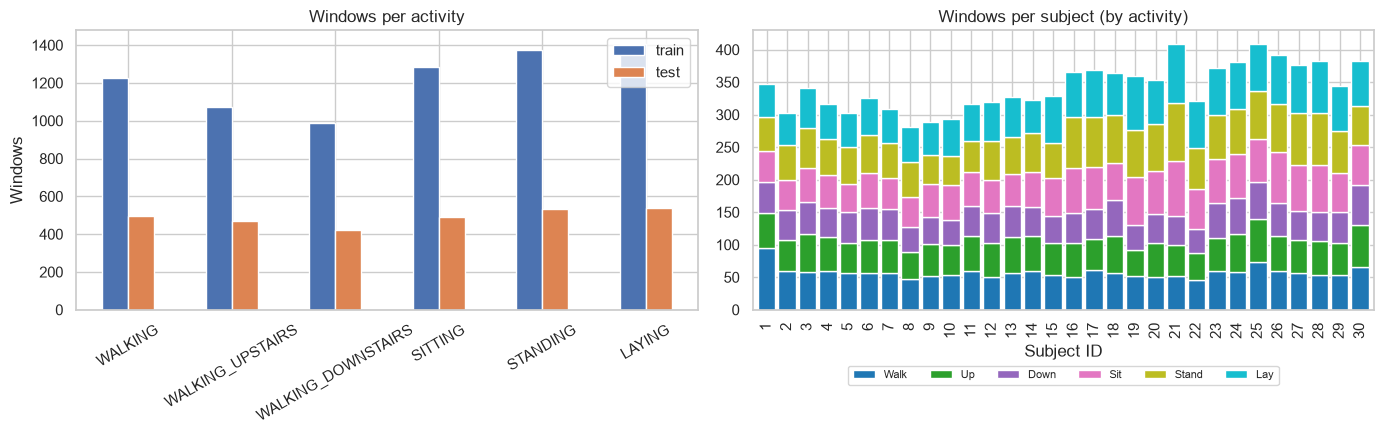

Windows per subject: min 281 max 409


In [2]:
counts = pd.DataFrame({
    "train": pd.Series(y_train).value_counts().sort_index(),
    "test": pd.Series(y_test).value_counts().sort_index(),
})
counts.index = labels
counts["total"] = counts.sum(axis=1)
counts["share"] = counts["total"] / counts["total"].sum()
display(counts)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
counts[["train", "test"]].plot.bar(ax=axes[0], rot=30)
axes[0].set_title("Windows per activity")
axes[0].set_ylabel("Windows")

per_subject = pd.crosstab(
    np.r_[groups, data.subject_test], np.r_[y_train, y_test]
)
per_subject.columns = short
per_subject.plot.bar(stacked=True, ax=axes[1], width=0.85, colormap="tab10")
axes[1].set_title("Windows per subject (by activity)")
axes[1].set_xlabel("Subject ID")
axes[1].legend(ncol=6, fontsize=8, loc="upper center",
               bbox_to_anchor=(0.5, -0.18))
fig.tight_layout()
save_figure(fig, "A_eda_class_balance")
plt.show()
print("Windows per subject: min", per_subject.sum(axis=1).min(),
      "max", per_subject.sum(axis=1).max())

**Observations.** Classes are reasonably balanced (13.7% to 18.9% of
windows each), so accuracy is not misleading, but we still report macro F1.
Each subject contributes 281 to 409 windows, and every subject performed
all six activities.

### 2.2 Feature ranges and 2-D projection

Feature value range: -1.0 to 1.0
Missing values: 0
Variance explained by PC1, PC2: [0.626 0.049]


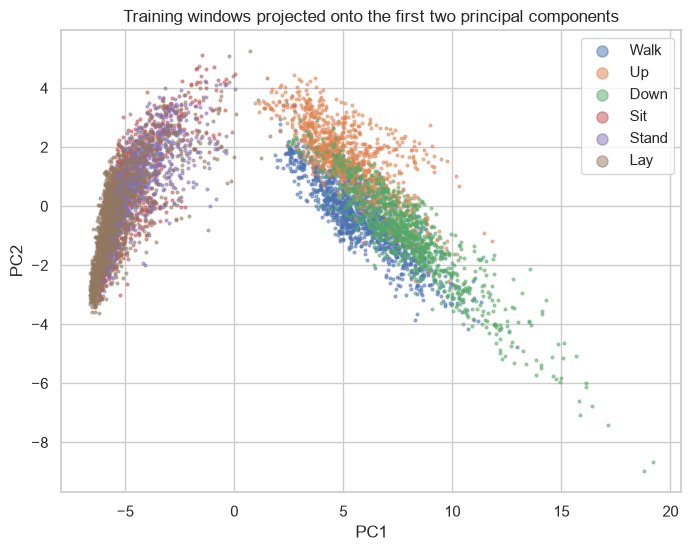

In [3]:
print("Feature value range:", X_train.values.min(), "to", X_train.values.max())
print("Missing values:", int(X_train.isna().sum().sum()))

pca = PCA(n_components=2, random_state=RANDOM_STATE)
Z = pca.fit_transform(X_train)
print("Variance explained by PC1, PC2:", pca.explained_variance_ratio_.round(3))

fig, ax = plt.subplots(figsize=(8, 6))
for code_, name in zip(sorted(ACTIVITY_NAMES), short):
    m = y_train == code_
    ax.scatter(Z[m, 0], Z[m, 1], s=4, alpha=0.5, label=name)
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("Training windows projected onto the first two principal components")
ax.legend(markerscale=4)
save_figure(fig, "A_eda_pca")
plt.show()

**Observations.** The features are already scaled to [-1, 1] with no
missing values, so preprocessing is minimal. PC1 alone explains 62.6% of
the variance and mostly separates **moving** (walking types) from **still**
(sit, stand, lay) activities. Within the still group, sitting and standing
overlap heavily in this projection, which previews where classifiers will
struggle.

### 2.3 What separates activities? Two example features

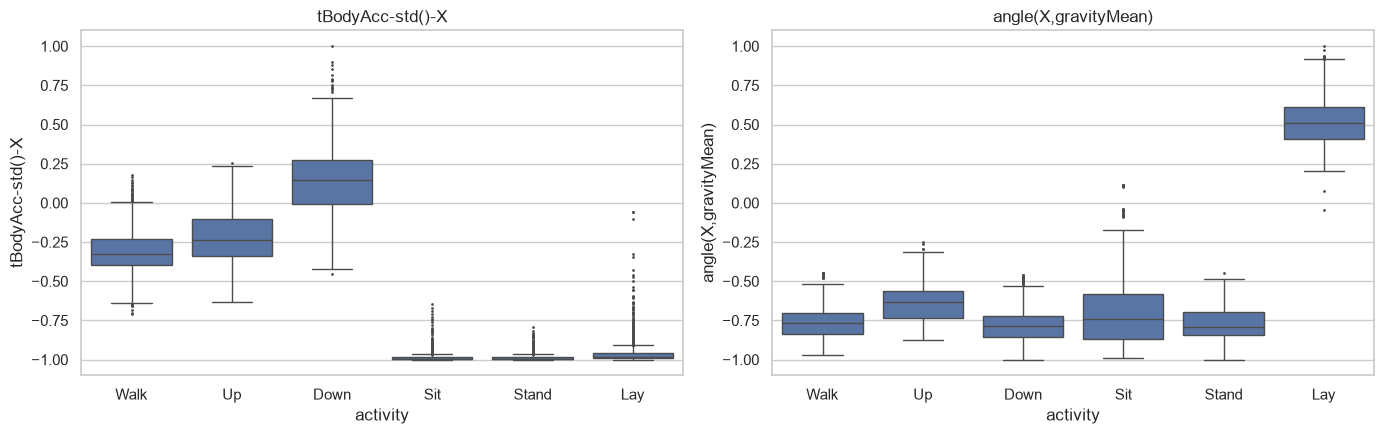

In [4]:
example_features = ["tBodyAcc-std()-X", "angle(X,gravityMean)"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
plot_df = X_train[example_features].copy()
plot_df["activity"] = pd.Categorical(
    [short[i - 1] for i in y_train], categories=short
)
for ax, feat in zip(axes, example_features):
    sns.boxplot(data=plot_df, x="activity", y=feat, ax=ax, fliersize=1)
    ax.set_title(feat)
fig.tight_layout()
save_figure(fig, "A_eda_example_features")
plt.show()

**Observations.** `tBodyAcc-std()-X` (how much the body shakes) cleanly
separates moving from still activities, and walking downstairs shakes the
most. `angle(X,gravityMean)` (phone orientation) isolates lying down, but
sitting and standing have nearly identical distributions on both features.

## 3. Baseline comparison (default settings, grouped CV)

In [5]:
def scaled(estimator):
    """Wrap an estimator in a standardization pipeline."""
    return make_pipeline(StandardScaler(), estimator)


models = {
    "Logistic Regression": scaled(LogisticRegression(max_iter=3000)),
    "Linear SVM": scaled(LinearSVC(max_iter=10000, random_state=RANDOM_STATE)),
    "RBF SVM": scaled(SVC()),
    "k-Nearest Neighbors": scaled(KNeighborsClassifier()),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
    "Gaussian Naive Bayes": GaussianNB(),
}

baseline_rows = {}
for name, model in models.items():
    baseline_rows[name] = cv_score(model, X_train, y_train, groups)
    print(f"{name:22s} macro F1 = {baseline_rows[name]['cv_f1_macro']:.4f}")

baseline = pd.DataFrame(baseline_rows).T.sort_values("cv_f1_macro", ascending=False)
save_results(baseline, "A_baseline_cv")
display(baseline)

Logistic Regression    macro F1 = 0.9331


Linear SVM             macro F1 = 0.9299


RBF SVM                macro F1 = 0.9219


k-Nearest Neighbors    macro F1 = 0.8625


Decision Tree          macro F1 = 0.8417


Random Forest          macro F1 = 0.9160


Gradient Boosting      macro F1 = 0.9334


Gaussian Naive Bayes   macro F1 = 0.6717


,cv_accuracy,cv_accuracy_std,cv_f1_macro,cv_f1_macro_std,cv_fit_time_s
Gradient Boosting,0.9330,0.0373,0.9334,0.0386,15.3687
Logistic Regression,0.9342,0.0395,0.9331,0.0425,1.3093
Linear SVM,0.9304,0.0369,0.9299,0.0388,14.4360
RBF SVM,0.9231,0.0408,0.9219,0.0445,1.1605
Random Forest,0.9171,0.0422,0.9160,0.0433,2.8295
k-Nearest Neighbors,0.8649,0.0244,0.8625,0.0267,0.0545
Decision Tree,0.8471,0.0301,0.8417,0.0326,2.3113
Gaussian Naive Bayes,0.6777,0.0800,0.6717,0.0776,0.0327


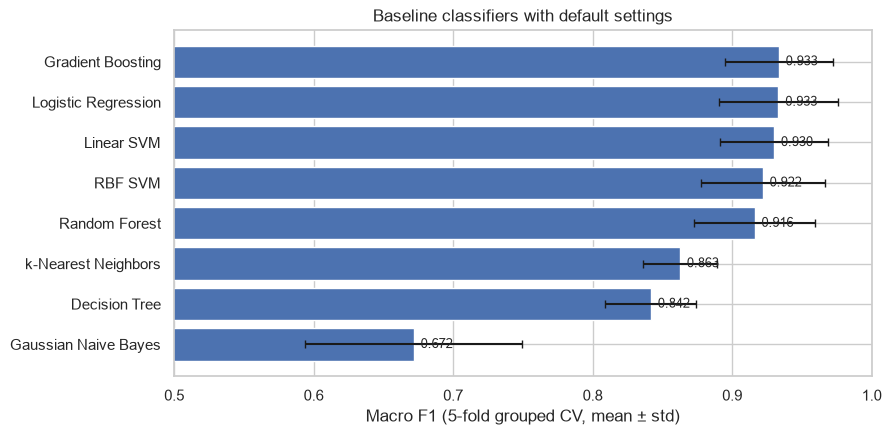

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(baseline.index[::-1], baseline["cv_f1_macro"][::-1],
        xerr=baseline["cv_f1_macro_std"][::-1], color="#4C72B0", capsize=3)
ax.set_xlim(0.5, 1.0)
ax.set_xlabel("Macro F1 (5-fold grouped CV, mean ± std)")
ax.set_title("Baseline classifiers with default settings")
for i, v in enumerate(baseline["cv_f1_macro"][::-1]):
    ax.text(v + 0.005, i, f"{v:.3f}", va="center", fontsize=9)
save_figure(fig, "A_baseline_cv")
plt.show()

**Observations.** Four models are effectively tied at about 0.93 macro F1:
gradient boosting, logistic regression, linear SVM, and RBF SVM. Their
differences (≤ 0.012) are much smaller than the fold-to-fold standard
deviation (about 0.04), which comes from which people land in each fold.
**Variation between people matters more than the choice among the top
models.** Gaussian Naive Bayes performs worst (0.67) because many of the
561 features are highly correlated (for example mean, max, and min of the
same signal), which violates its independence assumption.

## 4. Hyperparameter tuning

We tune the four best baseline models with `GridSearchCV`, using the same
subject-grouped folds and macro F1 as the selection metric.

In [7]:
param_grids = {
    "Logistic Regression": {"logisticregression__C": [0.01, 0.1, 1, 10, 100]},
    "Linear SVM": {"linearsvc__C": [0.001, 0.01, 0.1, 1, 10]},
    "RBF SVM": {"svc__C": [1, 10, 100, 1000],
                "svc__gamma": [1e-4, 3e-4, 1e-3, 3e-3]},
    "k-Nearest Neighbors": {"kneighborsclassifier__n_neighbors": [3, 5, 10, 20, 40],
                            "kneighborsclassifier__weights": ["uniform", "distance"]},
    "Decision Tree": {"max_depth": [5, 10, 20, None],
                      "min_samples_leaf": [1, 5, 20]},
    "Random Forest": {"n_estimators": [100, 300, 500],
                      "max_features": ["sqrt", "log2", 0.1]},
    "Gradient Boosting": {"learning_rate": [0.05, 0.1, 0.2],
                          "max_iter": [100, 300]},
    "Gaussian Naive Bayes": {"var_smoothing": [1e-9, 1e-6, 1e-3, 1e-1]},
}

top4 = list(baseline.index[:4])
print("Tuning:", top4)

searches = {}
for name in top4:
    start = time.perf_counter()
    search = GridSearchCV(clone(models[name]), param_grids[name],
                          scoring="f1_macro", cv=group_cv(), n_jobs=-1)
    search.fit(X_train, y_train, groups=groups)
    searches[name] = search
    print(f"{name:22s} best CV macro F1 = {search.best_score_:.4f} "
          f"({time.perf_counter() - start:.0f}s)  {search.best_params_}")

Tuning: ['Gradient Boosting', 'Logistic Regression', 'Linear SVM', 'RBF SVM']


Gradient Boosting      best CV macro F1 = 0.9354 (86s)  {'learning_rate': 0.2, 'max_iter': 300}


Logistic Regression    best CV macro F1 = 0.9339 (9s)  {'logisticregression__C': 0.1}


Linear SVM             best CV macro F1 = 0.9364 (68s)  {'linearsvc__C': 0.1}


RBF SVM                best CV macro F1 = 0.9316 (38s)  {'svc__C': 100, 'svc__gamma': 0.0001}


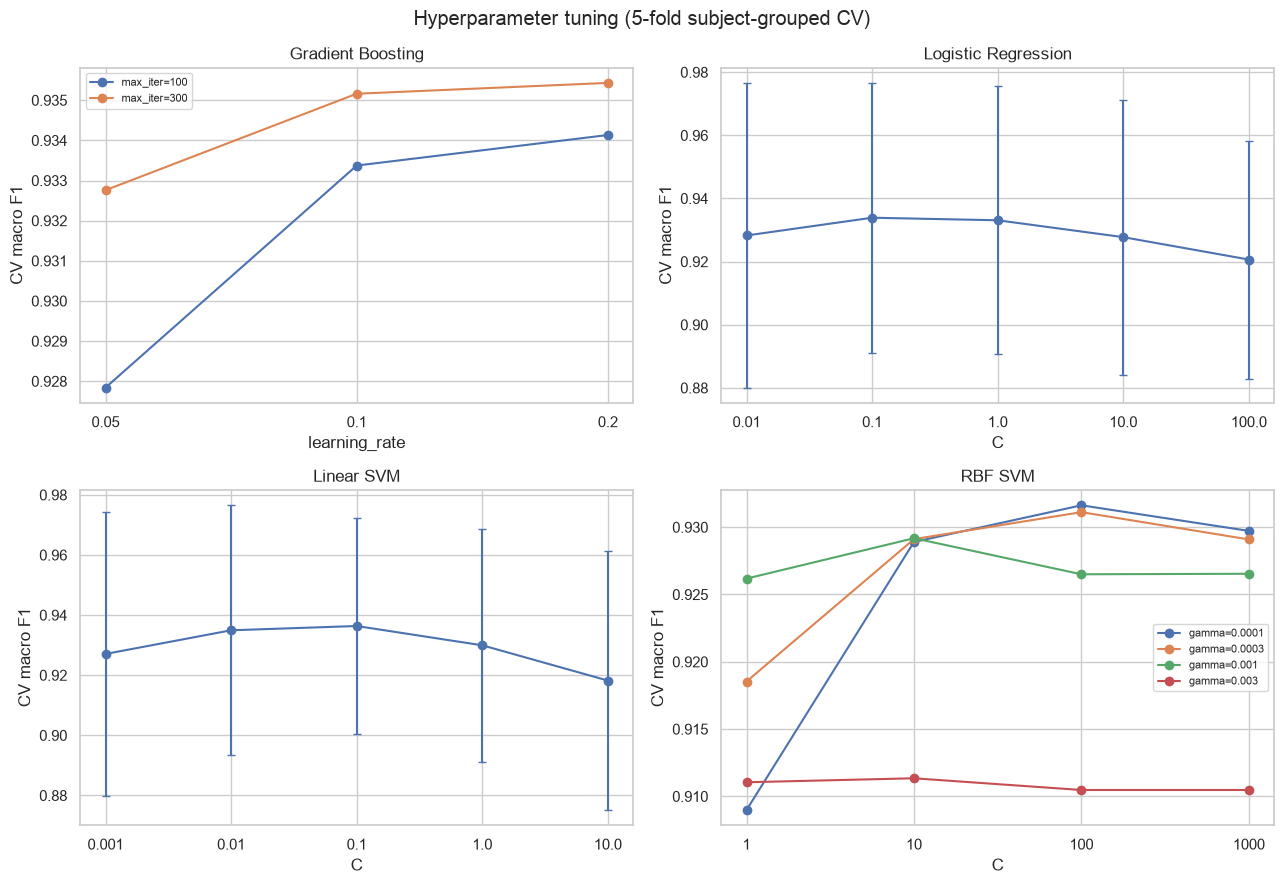

,baseline_cv_f1,tuned_cv_f1,best_params
Gradient Boosting,0.9334,0.9354,"{'learning_rate': 0.2, 'max_iter': 300}"
Logistic Regression,0.9331,0.9339,{'logisticregression__C': 0.1}
Linear SVM,0.9299,0.9364,{'linearsvc__C': 0.1}
RBF SVM,0.9219,0.9316,"{'svc__C': 100, 'svc__gamma': 0.0001}"


In [8]:
def plot_tuning(ax, name, search):
    """Plot CV score against the first parameter, one line per second parameter."""
    res = pd.DataFrame(search.cv_results_)
    params = list(param_grids[name])
    x_param = params[0]
    x_label = x_param.split("__")[-1]
    if len(params) == 1:
        res = res.sort_values(f"param_{x_param}")
        xs = res[f"param_{x_param}"].astype(str)
        ax.errorbar(xs, res["mean_test_score"], yerr=res["std_test_score"],
                    marker="o", capsize=3)
    else:
        hue = params[1]
        for value, grp in res.groupby(f"param_{hue}", dropna=False):
            grp = grp.sort_values(f"param_{x_param}",
                                  key=lambda s: s.astype(str))
            ax.plot(grp[f"param_{x_param}"].astype(str), grp["mean_test_score"],
                    marker="o", label=f"{hue.split('__')[-1]}={value}")
        ax.legend(fontsize=8)
    ax.set_title(name)
    ax.set_xlabel(x_label)
    ax.set_ylabel("CV macro F1")


fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, name in zip(axes.ravel(), top4):
    plot_tuning(ax, name, searches[name])
fig.suptitle("Hyperparameter tuning (5-fold subject-grouped CV)")
fig.tight_layout()
save_figure(fig, "A_tuning_curves")
plt.show()

tuning = pd.DataFrame({
    name: {"baseline_cv_f1": baseline.loc[name, "cv_f1_macro"],
           "tuned_cv_f1": s.best_score_,
           "best_params": s.best_params_}
    for name, s in searches.items()
}).T
save_results(tuning, "A_tuning_summary")
display(tuning)

**Observations.** Tuning gives only small gains: RBF SVM improves the most
(0.922 → 0.932, preferring large `C` with small `gamma`, i.e. a smoother
boundary), and the linear models prefer moderate regularization
(`C = 0.1`). Gradient boosting benefits from more iterations. All gains
are within the ±0.04 spread across folds, so the default settings were
already close to optimal for this data.

## 5. Final comparison on the held-out test set

Each model is refit on the full training set and scored once on the 9
unseen test subjects. The four tuned models use their best parameters;
the rest keep defaults. The final model is chosen by **CV score**, not
test score, to avoid selecting on the test set.

In [9]:
final_models = {name: clone(models[name]) for name in models}
for name, s in searches.items():
    final_models[name] = clone(s.best_estimator_)

final_rows, predictions = {}, {}
for name, model in final_models.items():
    metrics, y_pred = evaluate_on_test(model, X_train, y_train, X_test, y_test)
    metrics["tuned"] = name in searches
    metrics["cv_f1_macro"] = (searches[name].best_score_ if name in searches
                              else baseline.loc[name, "cv_f1_macro"])
    final_rows[name] = metrics
    predictions[name] = y_pred

final = pd.DataFrame(final_rows).T.sort_values("cv_f1_macro", ascending=False)
final = final[["tuned", "cv_f1_macro", "test_f1_macro", "test_accuracy",
               "fit_time_s", "predict_time_s"]]
save_results(final, "A_final_comparison")
best_name = final.index[0]
print("Selected model (highest CV macro F1):", best_name)
display(final)

Selected model (highest CV macro F1): Linear SVM


,tuned,cv_f1_macro,test_f1_macro,test_accuracy,fit_time_s,predict_time_s
Linear SVM,True,0.9364,0.9629,0.962,3.0118,0.0069
Gradient Boosting,True,0.9354,0.9377,0.9382,5.8371,0.0525
Logistic Regression,True,0.9339,0.95,0.9498,0.6431,0.0111
RBF SVM,True,0.9316,0.9561,0.9562,0.5666,0.8399
Random Forest,False,0.916,0.9234,0.925,0.8692,0.0155
k-Nearest Neighbors,False,0.8625,0.8766,0.8802,0.0215,0.1946
Decision Tree,False,0.8417,0.8598,0.8626,3.1016,0.0036
Gaussian Naive Bayes,False,0.6717,0.7672,0.7703,0.0179,0.0143


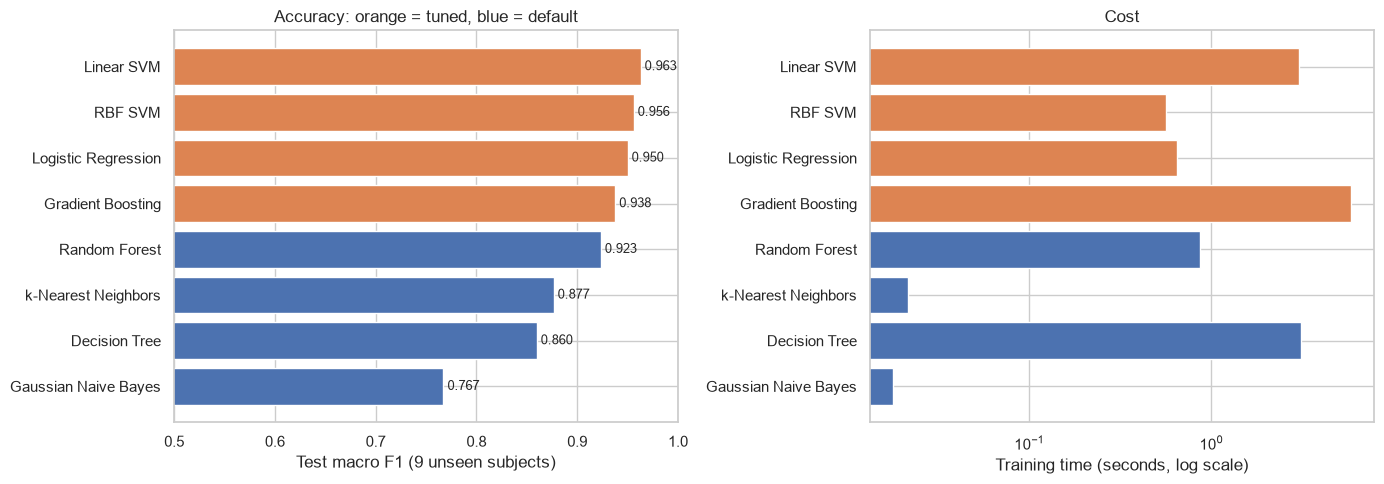

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
order = final.sort_values("test_f1_macro").index
colors = ["#DD8452" if final.loc[n, "tuned"] else "#4C72B0" for n in order]

axes[0].barh(order, final.loc[order, "test_f1_macro"].astype(float), color=colors)
axes[0].set_xlim(0.5, 1.0)
axes[0].set_xlabel("Test macro F1 (9 unseen subjects)")
axes[0].set_title("Accuracy: orange = tuned, blue = default")
for i, n in enumerate(order):
    v = float(final.loc[n, "test_f1_macro"])
    axes[0].text(v + 0.004, i, f"{v:.3f}", va="center", fontsize=9)

axes[1].barh(order, final.loc[order, "fit_time_s"].astype(float), color=colors)
axes[1].set_xscale("log")
axes[1].set_xlabel("Training time (seconds, log scale)")
axes[1].set_title("Cost")
fig.tight_layout()
save_figure(fig, "A_final_comparison")
plt.show()

**Observations.** The **tuned linear SVM** is selected (highest CV score)
and reaches **96.2% accuracy / 0.963 macro F1** on the 9 unseen test
subjects. The linear models and RBF SVM beat the tree ensembles, which
suggests the engineered features make the classes close to linearly
separable. Test scores are higher than CV scores because the CV folds
happen to include some harder training subjects; the ranking of the
top models is consistent across both. All models train in seconds,
so cost does not discriminate between them; RBF SVM and kNN are the
slowest to predict.

## 6. Error analysis

### 6.1 Confusion matrix of the selected model

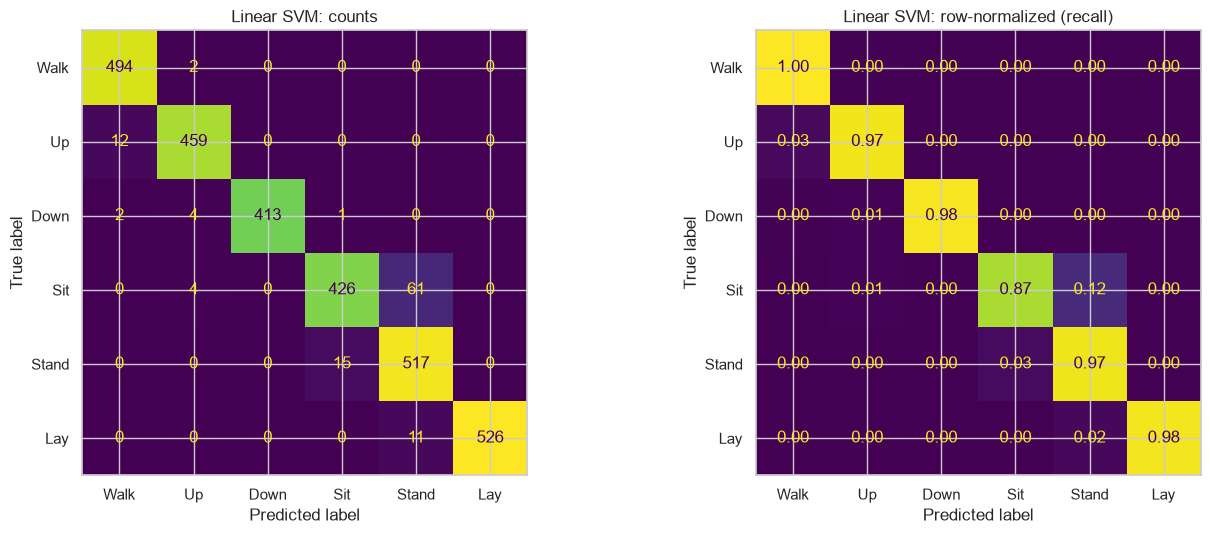

                    precision    recall  f1-score   support

           WALKING      0.972     0.996     0.984       496
  WALKING_UPSTAIRS      0.979     0.975     0.977       471
WALKING_DOWNSTAIRS      1.000     0.983     0.992       420
           SITTING      0.964     0.868     0.913       491
          STANDING      0.878     0.972     0.922       532
            LAYING      1.000     0.980     0.990       537

          accuracy                          0.962      2947
         macro avg      0.965     0.962     0.963      2947
      weighted avg      0.964     0.962     0.962      2947



In [11]:
y_best = predictions[best_name]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_best, display_labels=short, ax=axes[0], colorbar=False)
axes[0].set_title(f"{best_name}: counts")
ConfusionMatrixDisplay.from_predictions(
    y_test, y_best, display_labels=short, normalize="true",
    values_format=".2f", ax=axes[1], colorbar=False)
axes[1].set_title(f"{best_name}: row-normalized (recall)")
fig.tight_layout()
save_figure(fig, "A_confusion_matrix")
plt.show()

print(classification_report(y_test, y_best, target_names=labels, digits=3))

In [12]:
# Which confusions account for the errors, across every model?
pair_rows = {}
for name, y_pred in predictions.items():
    cm = confusion_matrix(y_test, y_pred)
    errors = cm.sum() - np.trace(cm)
    sit_stand = cm[3, 4] + cm[4, 3]
    walking = cm[:3, :3].sum() - np.trace(cm[:3, :3])
    pair_rows[name] = {"total_errors": errors,
                       "sit<->stand": sit_stand,
                       "among_walking_types": walking,
                       "sit_stand_share": sit_stand / errors if errors else 0}
pair_errors = pd.DataFrame(pair_rows).T.loc[final.index]
save_results(pair_errors, "A_error_breakdown")
display(pair_errors)

,total_errors,sit<->stand,among_walking_types,sit_stand_share
Linear SVM,112.0,76.0,20.0,0.6786
Gradient Boosting,182.0,102.0,79.0,0.5604
Logistic Regression,148.0,77.0,54.0,0.5203
RBF SVM,129.0,83.0,44.0,0.6434
Random Forest,221.0,98.0,123.0,0.4434
k-Nearest Neighbors,353.0,149.0,174.0,0.4221
Decision Tree,405.0,191.0,214.0,0.4716
Gaussian Naive Bayes,677.0,165.0,263.0,0.2437


**Observations.** For the selected linear SVM, **76 of its 112 test errors
(68%) are sitting ↔ standing confusions**, mostly sitting windows predicted
as standing (sitting recall 0.868). Confusions among the three walking
types are rare (20 errors). Every model shows the same pattern, so this is
a property of the data, not of one algorithm.

### 6.2 Sitting vs. standing: which features separate them?

We rank features by effect size (Cohen's *d*) between sitting and standing
windows in the **training** set.

In [13]:
sit, stand = X_train[y_train == 4], X_train[y_train == 5]
pooled_sd = np.sqrt((sit.var() + stand.var()) / 2)
cohen_d = ((stand.mean() - sit.mean()) / pooled_sd).rename("cohen_d")
effect = cohen_d.to_frame()
effect["abs_d"] = effect["cohen_d"].abs()
effect["sensor"] = np.where(effect.index.str.contains("Gyro"), "gyroscope",
                            "accelerometer")
effect = effect.sort_values("abs_d", ascending=False)
save_results(effect.head(20), "A_sit_stand_top_features")
display(effect.head(15))

print("Median |d| across all features:", round(effect["abs_d"].median(), 3))
print("Features with |d| > 1 (large effect):", int((effect["abs_d"] > 1).sum()))
print("Of the top 20, from the gyroscope:",
      int((effect.head(20)["sensor"] == "gyroscope").sum()))

,cohen_d,abs_d,sensor
tGravityAcc-max()-Y,-2.0402,2.0402,accelerometer
tGravityAcc-mean()-Y,-2.0338,2.0338,accelerometer
"angle(Y,gravityMean)",1.9931,1.9931,accelerometer
tGravityAcc-min()-Y,-1.9495,1.9495,accelerometer
fBodyGyro-meanFreq()-X,-1.1139,1.1139,gyroscope
"tGravityAcc-correlation()-X,Y",1.0317,1.0317,accelerometer
tGravityAcc-max()-Z,-0.9852,0.9852,accelerometer
"angle(Z,gravityMean)",0.9767,0.9767,accelerometer
tGravityAcc-mean()-Z,-0.9746,0.9746,accelerometer
tGravityAcc-min()-Z,-0.9504,0.9504,accelerometer


Median |d| across all features: 0.124
Features with |d| > 1 (large effect): 6
Of the top 20, from the gyroscope: 7


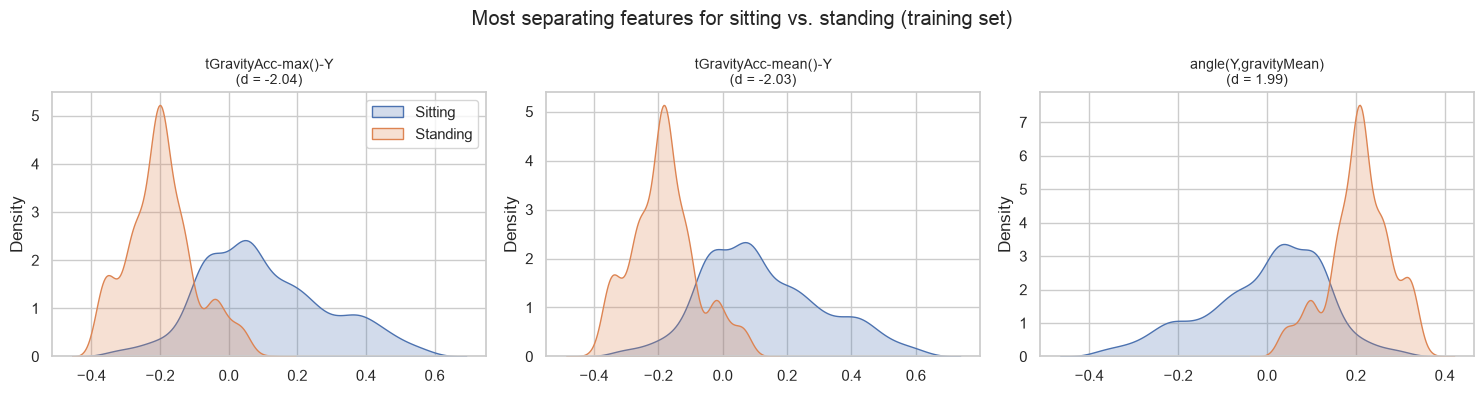

In [14]:
top3 = list(effect.index[:3])
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, feat in zip(axes, top3):
    sns.kdeplot(sit[feat], ax=ax, fill=True, label="Sitting")
    sns.kdeplot(stand[feat], ax=ax, fill=True, label="Standing")
    ax.set_title(f"{feat}\n(d = {effect.loc[feat, 'cohen_d']:.2f})", fontsize=10)
    ax.set_xlabel("")
axes[0].legend()
fig.suptitle("Most separating features for sitting vs. standing (training set)")
fig.tight_layout()
save_figure(fig, "A_sit_stand_distributions")
plt.show()

**Observations.** The features that best separate sitting from standing
are the **gravity components along the Y axis** (|d| ≈ 2). The phone sits
at the waist, so these measure the **tilt of the torso and hips**, which
changes slightly when a person sits. Only 6 of 561 features have a large
effect (|d| > 1), and even the best features overlap between classes,
which explains the residual confusion. 7 of the top 20 separating
features come from the gyroscope, so dropping the gyroscope (Person B's
sensor experiment) may hurt this pair the most.

### 6.3 Is the confusion spread evenly across people?

,overall_accuracy,sit_stand_windows,sit_stand_errors,sit_stand_error_rate
subject,,,,
9,0.9028,95,23,0.2421
10,0.8537,98,22,0.2245
4,0.9685,106,9,0.0849
12,0.9688,112,9,0.0804
20,0.9774,139,6,0.0432
2,0.9868,100,4,0.0400
18,0.9835,130,2,0.0154
24,0.9974,137,1,0.0073
13,0.9939,106,0,0.0000


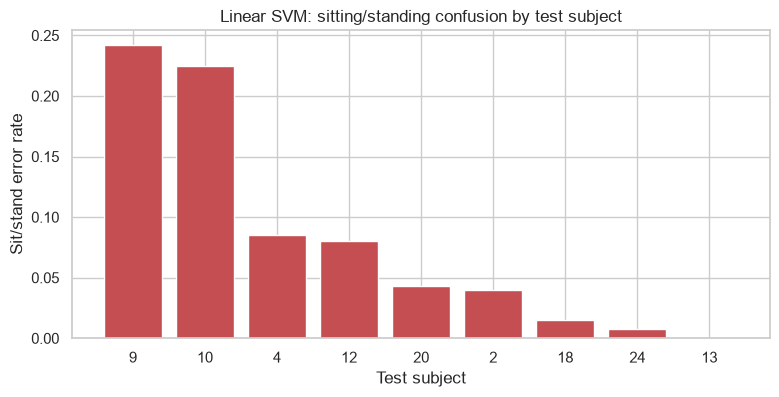

In [15]:
subj_test = data.subject_test
rows = []
for s in np.unique(subj_test):
    m = subj_test == s
    yt, yp = y_test[m], y_best[m]
    still = np.isin(yt, [4, 5])
    rows.append({
        "subject": s,
        "overall_accuracy": (yt == yp).mean(),
        "sit_stand_windows": int(still.sum()),
        "sit_stand_errors": int(((yt == 4) & (yp == 5)).sum()
                                + ((yt == 5) & (yp == 4)).sum()),
    })
by_subject = pd.DataFrame(rows).set_index("subject")
by_subject["sit_stand_error_rate"] = (by_subject["sit_stand_errors"]
                                      / by_subject["sit_stand_windows"])
by_subject = by_subject.sort_values("sit_stand_error_rate", ascending=False)
save_results(by_subject, "A_sit_stand_by_subject")
display(by_subject)

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(by_subject.index.astype(str), by_subject["sit_stand_error_rate"],
       color="#C44E52")
ax.set_xlabel("Test subject")
ax.set_ylabel("Sit/stand error rate")
ax.set_title(f"{best_name}: sitting/standing confusion by test subject")
save_figure(fig, "A_sit_stand_by_subject")
plt.show()

**Observations.** The confusion is **concentrated in a few people**:
subjects 9 and 10 account for 45 of the 76 sitting/standing errors (error
rates of 24% and 22%), while most other subjects are below 9%, and
subject 13 has none. A plausible explanation is differences in posture or
in how the phone was worn, which shifts the gravity-angle features the
model relies on. This links to Person C's generalization analysis.

### 6.4 Does a dedicated sitting-vs-standing model help?

A two-stage idea: the general model predicts the activity, and any window
predicted as sitting or standing is passed to a specialist model trained
only on sitting and standing windows. The specialist is tuned with the same
subject-grouped CV.

In [16]:
still_train = np.isin(y_train, [4, 5])
spec_search = GridSearchCV(
    scaled(SVC()),
    {"svc__C": [0.1, 1, 10, 100], "svc__gamma": [1e-4, 3e-4, 1e-3, 3e-3]},
    scoring="f1_macro", cv=group_cv(), n_jobs=-1,
)
spec_search.fit(X_train[still_train], y_train[still_train],
                groups=groups[still_train])
print("Specialist best CV macro F1:", round(spec_search.best_score_, 4),
      spec_search.best_params_)

y_two_stage = y_best.copy()
routed = np.isin(y_best, [4, 5])
y_two_stage[routed] = spec_search.predict(X_test[routed])

still_test = np.isin(y_test, [4, 5])
compare = pd.DataFrame({
    "sit/stand accuracy": [(y_best == y_test)[still_test].mean(),
                           (y_two_stage == y_test)[still_test].mean()],
    "overall accuracy": [(y_best == y_test).mean(),
                         (y_two_stage == y_test).mean()],
}, index=[best_name, f"{best_name} + specialist"])
save_results(compare, "A_two_stage")
display(compare)

Specialist best CV macro F1: 0.927 {'svc__C': 100, 'svc__gamma': 0.0001}


,sit/stand accuracy,overall accuracy
Linear SVM,0.9218,0.962
Linear SVM + specialist,0.9277,0.964


**Observations.** A dedicated sitting-vs-standing model barely helps
(sit/stand accuracy 92.2% → 92.8%; overall 96.2% → 96.4%). The remaining
errors are not caused by a lack of model capacity: for the hard subjects,
the features themselves do not contain enough signal to separate the
two postures. Improving this would require better information (for
example personal calibration, or the raw signals), not a more complex
classifier.

## 7. Summary

| Finding | Evidence |
|---|---|
| The top four models are statistically tied | CV macro F1 0.930–0.936 after tuning, fold std ≈ 0.04 |
| Selected model: tuned linear SVM (`C = 0.1`) | Test accuracy 96.2%, macro F1 0.963, trains in ~3 s |
| Tuning helps only slightly | Largest gain +0.010 (RBF SVM) |
| Most errors are sitting ↔ standing | 68% of the selected model's errors; same pattern for every model |
| The deciding signal is torso tilt (gravity, Y axis) | Cohen's d ≈ 2 for the top features |
| The errors come from specific people | Subjects 9 and 10 cause 45 of 76 sit/stand errors |
| A specialist sit/stand model is not worth it | +0.6 points on sit/stand, +0.2 overall |

**Takeaway for the report.** On this dataset, the choice among good
classifiers matters less than *who* the model is used on. A simple, fast
linear model is sufficient, and the remaining errors come from postures
that look alike to a waist-mounted phone for some people. This motivates
Person B's question (how much of the 561-feature input is really needed)
and Person C's question (how well models transfer to new people).

**Limitations.** Only 9 test subjects, so the per-subject results are
noisy. Tuning used coarse grids. Timing numbers are from a single laptop
run and are only comparable within this notebook.
